# Wadi Ghadir gravity – open-source workflow, from readings to maps

**Wadi Ghadir, Eastern Desert, Egypt · Scintrex CG-6 · 16–24 January 2026**

**Prepared by Dr. Mohamed Sobh, LIAG** (Leibniz Institute for Applied Geophysics)

This notebook processes the Wadi Ghadir gravity data from the raw CG-6 files to interpretation maps. It uses
open-source geophysics software at every step where one exists:

| Step | Open-source tool | Used for |
|---|---|---|
| 3 | **pygtide** (Python wrapper of **ETERNA** PREDICT, Wenzel 1996) | Earth tide from a full tidal potential catalogue |
| 9 | **Boule** (Fatiando a Terra) | Normal gravity of the WGS84 ellipsoid at the station height → gravity disturbance |
| 10 | **Harmonica** + **Choclo** (Fatiando a Terra) | Bouguer correction; prism kernels checked against the slab |
| 11 | **Harmonica** `prism_layer` / `prism_gravity` | Terrain (topographic) effect from the Copernicus DEM |
| 13 | **Verde** + **Harmonica** `EquivalentSources` | Gridding with cross-validation |
| 14 | **Harmonica** filters (`upward_continuation`, `gaussian_highpass`) | Regional–residual separation |
| 15 | **SGTool** (Jessell et al.) and **Harmonica** | Derivatives, total horizontal gradient, tilt angle, analytic signal |
| 16 | **PyGMT** (Generic Mapping Tools) | Publication maps |

The survey-specific steps (CG-6 reading, QC, GNSS matching, base control, instrument calibration, Nettleton
density) use the `wghadir` package of this project, because no general open-source tool covers them.

**How to use it:** every step has a **✏️ PARAMETERS** cell, a **▶ PROCESSING** cell and a **📊 RESULT** cell.
Change a parameter, then re-run that step and everything below it. Results are written to
`outputs/open_source/`; the delivered products in `outputs/` are not touched.

## 0  Set-up and software versions

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 82}}
import datetime as dt
import json
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

REPO = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
if os.path.abspath(REPO) not in sys.path:
    sys.path.insert(0, os.path.abspath(REPO))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*etddt.dat.*")        # pygtide: old leap-second table (see step 3)

import boule as bl
import choclo
import harmonica as hm
import pyproj
import pygmt
import verde as vd
import xrft
try:
    import pygtide
except ImportError:          # pygtide needs a Fortran build; the notebook then falls back to Longman (1959)
    pygtide = None

from wghadir.common import geodata, mapping
from wghadir.common.sgtool_bridge import sgtool_processor
from wghadir.gravity import (base_control, density, instruments, inventory, positioning, qc, reductions, settings,
                             terrain)
from wghadir.gravity.tide import longman_correction

RAW_DIR = os.path.join(REPO, "data", "raw")
EXTERNAL_DIR = os.path.join(REPO, "data", "external")
OUT_DIR = os.path.join(REPO, "outputs", "open_source")
os.makedirs(OUT_DIR, exist_ok=True)
UTM = pyproj.Proj("EPSG:32636")           # UTM zone 36N for all projected work
COLOR = mapping.INST_COL
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

with pygmt.clib.Session() as _lib:
    GMT_VERSION = _lib.info["version"]
pd.DataFrame({"package": ["harmonica", "verde", "boule", "choclo", "pygtide (ETERNA)", "pygmt", "GMT", "SGTool"],
              "version": [hm.__version__, vd.__version__, bl.__version__, choclo.__version__,
                          getattr(pygtide, "__version__", "not installed"), pygmt.__version__,
                          GMT_VERSION,
                          "vendored, commit 1a68e09 (third_party/sgtool)"]})

,package,version
0,harmonica,v0.7.0
1,verde,v1.9.0
2,boule,v0.6.0
3,choclo,v0.3.2
4,pygtide (ETERNA),0.9.7
5,pygmt,v0.17.0
6,GMT,6.5.0
7,SGTool,"vendored, commit 1a68e09 (third_party/sgtool)"


## 1  Read the CG-6 data

Both CG-6 exports are read completely (`inventory.load_instruments`). The CG-6 stores
`CorrGrav = RawGrav + TideCorr + TiltCorr + TempCorr + DriftCorr`, which is checked for every reading.

In [2]:
# ▶ PROCESSING
headers, rows = inventory.load_instruments(RAW_DIR)
files, meta = inventory.inventory_tables(headers, rows, RAW_DIR)
corrgrav_check = inventory.verify_corrgrav(rows)
print(f"{len(rows)} readings from {rows['instrument'].nunique()} instruments")
display(corrgrav_check[["instrument", "rows_checked", "closure_rms_mgal", "closure_max_abs_mgal"]])
rows.groupby(["Date", "instrument"]).size().unstack().fillna(0).astype(int).T

1519 readings from 2 instruments


,instrument,rows_checked,closure_rms_mgal,closure_max_abs_mgal
0,CG6-0313,724,0.000067,0.0002
1,CG6-0640,795,0.000065,0.0002


Date,2026-01-16,2026-01-17,2026-01-18,2026-01-19,2026-01-20,2026-01-21,2026-01-22,2026-01-23,2026-01-24
instrument,,,,,,,,,
CG6-0313,149,61,64,39,58,62,93,110,88
CG6-0640,148,70,95,69,99,52,95,105,62


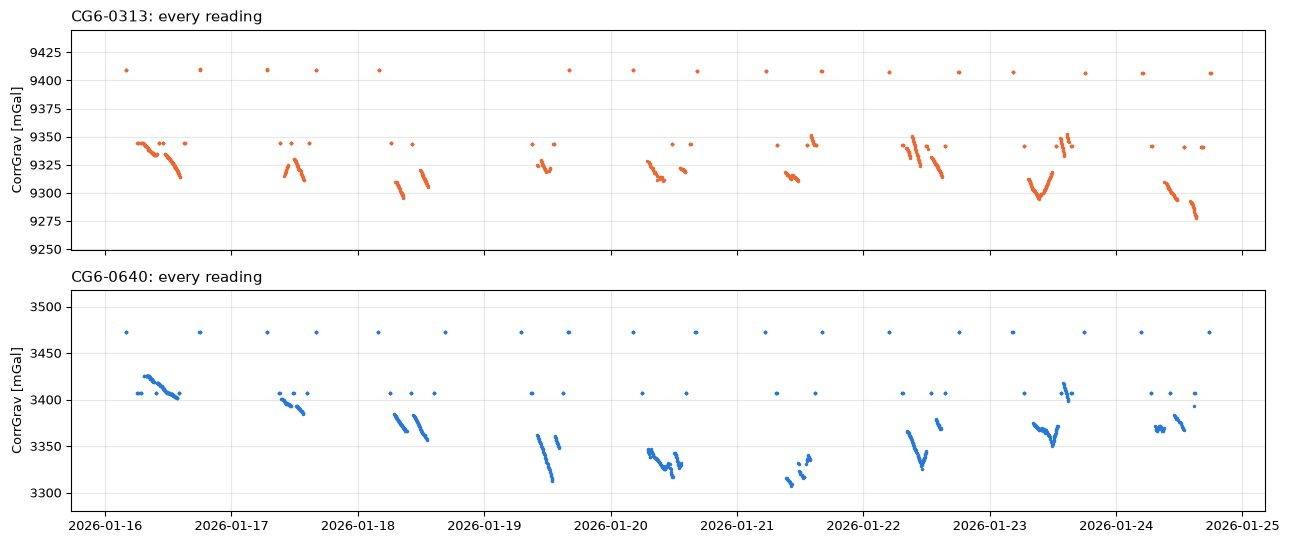

In [3]:
# 📊 RESULT
fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
for ax, (inst, d) in zip(axes, rows.groupby("instrument")):
    lo, hi = d["CorrGrav"].quantile([0.05, 0.95])
    ax.plot(d["time_utc"], d["CorrGrav"], ".", ms=3, color=COLOR[inst])
    ax.set(ylim=(lo - 0.3 * (hi - lo), hi + 0.3 * (hi - lo)), ylabel="CorrGrav [mGal]")
    ax.set_title(f"{inst}: every reading", loc="left")
plt.tight_layout()

## 2  Earth tide reference: Longman (1959)

The CG-6 computes the Longman (1959) tide on board. It is recomputed here at the CG-6 GPS position with the time
stamps as UTC (`inventory.tide_recompute`). For #0313 the user position in the instrument was left at Toronto, so the
on-board tide of that instrument is wrong. The Longman tide is the reference for the ETERNA tide in step 3.

In [4]:
# ▶ PROCESSING
tide_check = inventory.tide_recompute(rows)          # adds tide_longman_gps (mGal, a correction to ADD)
tide_check

,instrument,model,rms_ugal,max_abs_ugal
0,CG6-0313,"Longman at user-entered position, t as UTC",0.208277,0.419939
1,CG6-0313,"Longman at CG-6 GPS position, t as UTC",89.635109,215.077120
2,CG6-0313,"Longman at user position, t shifted -3 h",73.853237,134.167015
3,CG6-0313,"Longman at user position, t shifted -2 h",50.309270,92.844010
4,CG6-0313,"Longman at user position, t shifted +2 h",48.744666,93.288906
5,CG6-0313,"Longman at user position, t shifted +3 h",68.261942,134.598188
6,CG6-0640,"Longman at user-entered position, t as UTC",0.193739,0.433270
7,CG6-0640,"Longman at CG-6 GPS position, t as UTC",1.830581,3.115111
8,CG6-0640,"Longman at user position, t shifted -3 h",70.043101,152.495267
9,CG6-0640,"Longman at user position, t shifted -2 h",49.998658,98.930594


## 3  Earth tide with ETERNA (pygtide)

**pygtide** runs ETERNA PREDICT (Wenzel 1996), the standard Earth-tide program of the tidal gravity
community. It uses a full tidal potential catalogue (Hartmann & Wenzel 1995) and standard elastic Earth response
factors, rather than Longman's closed formula with one factor of 1.16. The tide is predicted at the survey centre
as a 1-minute series and interpolated to every reading. Over a 30 km survey the tide changes by less than 1 µGal.

The tidal **signal** in nm/s² is converted to a **correction** in mGal: correction = −signal × 10⁻⁴.

`TIDE_MODEL` selects the tide used for the rest of the processing:
* `"eterna"`: pygtide/ETERNA (the default here);
* `"longman"`: Longman at the GPS position, as in the delivered products;
* `"onboard"`: the CG-6 value (wrong for #0313).

pygtide warns that its leap-second table ends in 2017. The resulting time error of about one second changes the
tide by much less than 1 µGal.

In [5]:
# ✏️ PARAMETERS – edit and re-run from here
TIDE_MODEL = "eterna"                 # "eterna" | "longman" | "onboard"
TIDE_SAMPLING_S = 60                  # ETERNA prediction interval
TIDE_CONTROL = {}                     # extra ETERNA control parameters, e.g. {"tidalpoten": 8}
SHOW_DAY = "2026-01-18"

In [6]:
# ▶ PROCESSING
lat_c, lon_c = float(rows["LatGPS"].median()), float(rows["LonGPS"].median())
t_read = pd.to_datetime(rows["time_utc"])
t0 = t_read.min().floor("D")
if pygtide is not None:
    hours = int(np.ceil((t_read.max() - t0) / pd.Timedelta(hours=1))) + 1
    pt = pygtide.pygtide(msg=False)
    pt.predict(lat_c, lon_c, 150.0, t0.to_pydatetime(), hours, TIDE_SAMPLING_S, tidalcompo=0, **TIDE_CONTROL)
    eterna = pt.results()
    sec_model = (eterna["UTC"].dt.tz_localize(None) - t0).dt.total_seconds().values
    sec_read = (t_read - t0).dt.total_seconds().values
    rows["tide_eterna"] = -1e-4 * np.interp(sec_read, sec_model, eterna["Signal [nm/s**2]"].values)
else:
    print("pygtide not available - ETERNA replaced by Longman")
    rows["tide_eterna"] = rows["tide_longman_gps"]

tide_used = {"eterna": rows["tide_eterna"], "longman": rows["tide_longman_gps"], "onboard": rows["TideCorr"]}[TIDE_MODEL]
rows["g_tidefix"] = rows["CorrGrav"] - rows["TideCorr"] + tide_used          # used by all later steps
d = 1000 * (rows["tide_eterna"] - rows["tide_longman_gps"])
print(f"tide used: {TIDE_MODEL};  ETERNA − Longman: rms {np.sqrt(np.mean(d ** 2)):.1f} µGal, max {d.abs().max():.1f} µGal")

tide used: eterna;  ETERNA − Longman: rms 7.0 µGal, max 15.7 µGal


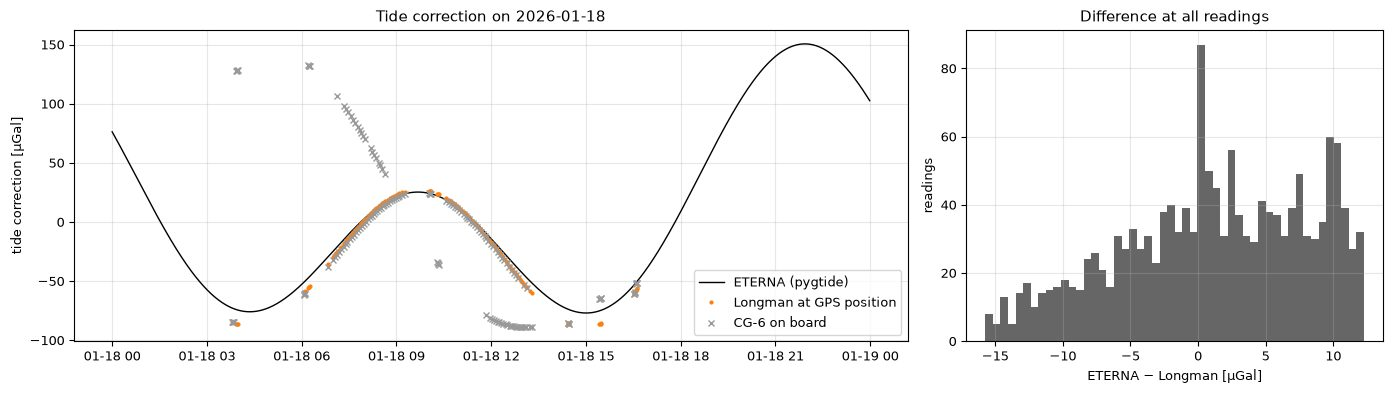

In [7]:
# 📊 RESULT
day = rows[rows["Date"] == SHOW_DAY].sort_values("time_utc")
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
if pygtide is not None:
    m = eterna[eterna["UTC"].dt.strftime("%Y-%m-%d") == SHOW_DAY]
    axes[0].plot(m["UTC"].dt.tz_localize(None), -1e-1 * m["Signal [nm/s**2]"], "-", color="k", lw=1, label="ETERNA (pygtide)")
axes[0].plot(day["time_utc"], 1000 * day["tide_longman_gps"], ".", ms=4, color="C1", label="Longman at GPS position")
axes[0].plot(day["time_utc"], 1000 * day["TideCorr"], "x", ms=4, color="0.6", label="CG-6 on board")
axes[0].set(ylabel="tide correction [µGal]", title=f"Tide correction on {SHOW_DAY}")
axes[0].legend()
axes[1].hist(d, bins=50, color="0.4")
axes[1].set(xlabel="ETERNA − Longman [µGal]", ylabel="readings", title="Difference at all readings")
plt.tight_layout()

## 4  Quality control

Each reading gets an accept/reject decision with reasons (`qc.row_qc`): overflow fields, frozen sensor output,
gross values, StdDev, tilt, and repeat outliers. The thresholds are in `TH`.

In [8]:
# ✏️ PARAMETERS – edit and re-run from here
TH = dict(settings.THRESHOLDS)        # e.g. TH["stddev_reject_mgal"] = 0.05

In [9]:
# ▶ PROCESSING
rows = qc.row_qc(rows, th=TH)
print(f"accepted {rows['accepted'].sum()} of {len(rows)} readings")
rows.loc[~rows["accepted"], "reject_reasons"].value_counts().rename("rejected").to_frame()

accepted 1472 of 1519 readings


,rejected
reject_reasons,
FROZEN_SENSOR_OUTPUT,27
REPEAT_OUTLIER,8
STDDEV_GT_0.080,4
TILT_GT_30,3
OVERFLOW_FIELD;GROSS_RANGE_GT_500;TILT_GT_30,2
GROSS_RANGE_GT_500,1
GROSS_RANGE_GT_500;TILT_GT_30,1
OVERFLOW_FIELD,1


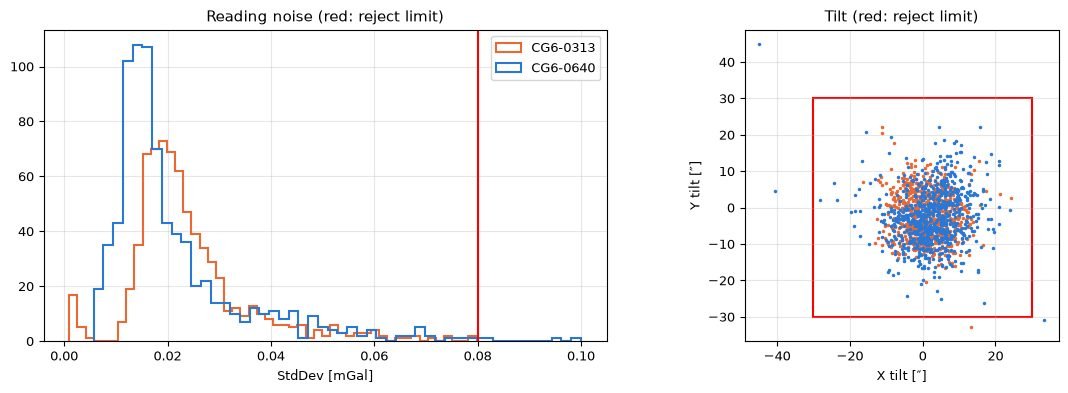

In [10]:
# 📊 RESULT
ok = rows["overflow_fields"].eq("")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for inst, d in rows[ok].groupby("instrument"):
    axes[0].hist(d["StdDev"].clip(upper=0.1), bins=50, histtype="step", lw=1.5, color=COLOR[inst], label=inst)
    axes[1].plot(d["X"].clip(-45, 45), d["Y"].clip(-45, 45), ".", ms=3, color=COLOR[inst])
axes[0].axvline(TH["stddev_reject_mgal"], color="r")
axes[0].set(xlabel="StdDev [mGal]", title="Reading noise (red: reject limit)")
axes[0].legend()
t = TH["tilt_reject_arcsec"]
axes[1].add_patch(plt.Rectangle((-t, -t), 2 * t, 2 * t, fill=False, ec="r", lw=1.5))
axes[1].set(xlabel="X tilt [″]", ylabel="Y tilt [″]", title="Tilt (red: reject limit)", aspect="equal")
plt.tight_layout()

## 5  Occupations, GNSS positions and heights

Accepted readings at one station are averaged into occupations (`inventory.build_occupations`). Each occupation is
matched to one GNSS point (`positioning.*`, report §3.3), and orthometric heights are computed with the EGM2008 geoid.
The Copernicus GLO-30 DEM is loaded for the terrain correction.

In [11]:
# ✏️ PARAMETERS – edit and re-run from here
MATCH = dict(max_dist_m=settings.MATCH_MAX_M, ambig_margin_m=settings.AMBIG_MARGIN_M,
             distinct_loc_m=settings.DISTINCT_LOC_M)

In [12]:
# ▶ PROCESSING
occ = inventory.build_occupations(rows)
gnss_points, _, master_check, _ = positioning.load_gnss(RAW_DIR)
datum_marks, datum_days, ref = positioning.gnss_datum_check(gnss_points)
day_map, day_of_date = positioning.map_days(occ, gnss_points)
occ = positioning.match_occupations(occ, gnss_points, day_of_date, datum_days, ref, **MATCH)
b = datum_marks[datum_marks["mark"] == "base_100"].merge(datum_days[["gnss_day", "day_height_shift_m"]], on="gnss_day")
ref["base_100"]["h_used"] = float((b["h_gnss"] - b["day_height_shift_m"]).median())
dem = geodata.Grid(geodata.fetch_dem(settings.DEM_BOUNDS, os.path.join(EXTERNAL_DIR, settings.DEM_FILE)))
geoid = geodata.Grid(geodata.fetch_geoid(settings.DEM_BOUNDS, os.path.join(EXTERNAL_DIR, settings.GEOID_FILE)))
occ = positioning.add_orthometric(occ, ref, geoid, dem)
print(f"{len(occ)} occupations; matched: {occ['match_status'].isin(settings.MATCH_OK).sum()}")
print("base 100:", {k: round(v, 4) if isinstance(v, float) else v for k, v in ref["base_100"].items()})

1116 occupations; matched: 1092
base 100: {'h': np.float64(111.77), 'lat': np.float64(24.7867), 'lon': np.float64(34.9338), 'h_used': 111.77, 'N_egm2008': 11.881, 'H_used': 99.889, 'H_dem': 100.4564}


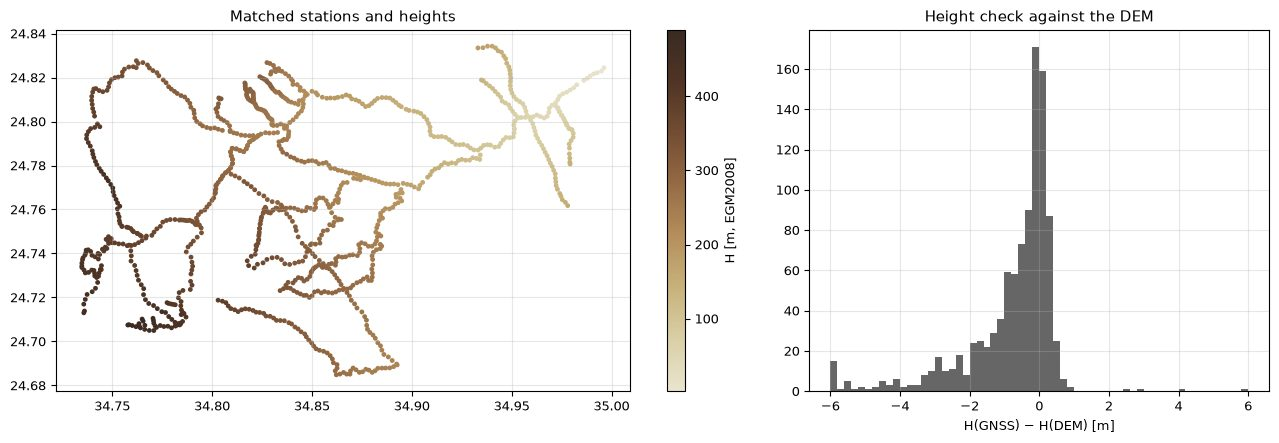

In [13]:
# 📊 RESULT
f = occ[(occ["role"] == "field") & occ["match_status"].isin(settings.MATCH_OK)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
sc = axes[0].scatter(f["lon"], f["lat"], c=f["H_ortho_m"], s=6, cmap=mapping.HYPSO)
plt.colorbar(sc, ax=axes[0], label="H [m, EGM2008]")
axes[0].set(aspect=1 / np.cos(np.radians(24.76)), title="Matched stations and heights")
axes[1].hist(f["H_minus_dem_m"].clip(-6, 6), bins=60, color="0.4")
axes[1].set(xlabel="H(GNSS) − H(DEM) [m]", title="Height check against the DEM")
plt.tight_layout()

## 6  Base control and drift

The drift of each instrument is modelled piecewise linearly between base-100 readings (`base_control.base_control`);
every occupation then has Δg₁₀₀, its gravity relative to base 100.

In [14]:
# ✏️ PARAMETERS – edit and re-run from here
TIE_MAX_HOURS, TARE_MGAL = settings.TIE_MAX_HOURS, settings.TARE_MGAL

In [15]:
# ▶ PROCESSING
(occ, ctrl, ties, tie_stats, loo, seg_rates, model_sigma,
 rate_sigma) = base_control.base_control(occ, ref, tie_max_hours=TIE_MAX_HOURS, tare_mgal=TARE_MGAL)
print("drift-model uncertainty [mGal]:", {k: round(v, 4) for k, v in model_sigma.items()})

drift-model uncertainty [mGal]: {'CG6-0313': 0.0594, 'CG6-0640': 0.0119}


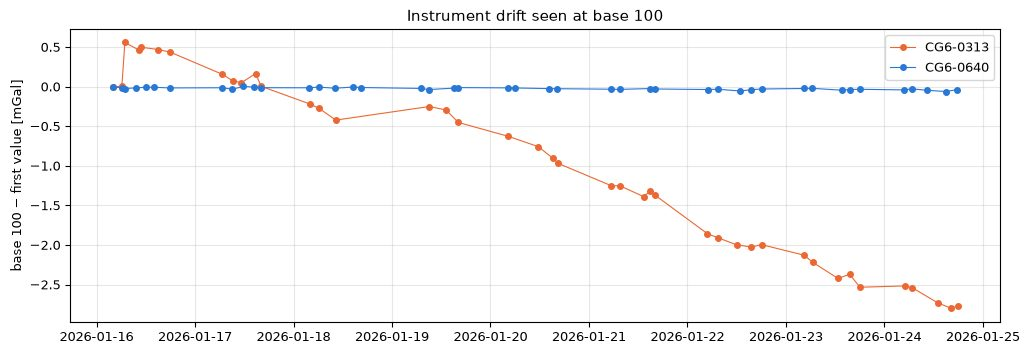

In [16]:
# 📊 RESULT
fig, ax = plt.subplots(figsize=(12, 3.8))
for inst, d in ctrl.groupby("instrument"):
    ax.plot(pd.to_datetime(d["t"]), d["g100"] - d["g100"].iloc[0], "o-", ms=4, lw=0.8, color=COLOR[inst], label=inst)
ax.set(ylabel="base 100 − first value [mGal]", title="Instrument drift seen at base 100")
ax.legend()

## 7  Inter-instrument calibration

CG-6 #0313 is scaled to #0640 with the factor estimated from the hotel–base-100 ties and from co-located points
(`instruments.*`, report §3.5).

In [17]:
# ▶ PROCESSING
pairs = instruments.colocated_pairs(occ)
scale = instruments.scale_estimates(tie_stats, pairs)
z = (scale["k_colocated_origin"] - scale["k_tie"]) / np.hypot(scale["k_colocated_origin_se"], scale["k_tie_se"])
w1, w2 = 1 / scale["k_tie_se"] ** 2, 1 / scale["k_colocated_origin_se"] ** 2
k_apply = (w1 * scale["k_tie"] + w2 * scale["k_colocated_origin"]) / (w1 + w2) if abs(z) < 2 else None
if k_apply is not None:
    occ, retie = instruments.retie_extrapolated(occ, pairs, k_apply)
print(f"k(ties) = {scale['k_tie']:.5f}, k(co-located) = {scale['k_colocated_origin']:.5f}, z = {z:.2f} -> k applied = {k_apply}")

k(ties) = 1.01170, k(co-located) = 1.01358, z = 1.57 -> k applied = 1.0118519365095862


## 8  Free-air anomaly (classical)

The classical free-air anomaly relative to base 100 (`reductions.reductions`) uses the WGS84 normal gravity on the
ellipsoid, the second-order free-air term and **orthometric** heights H.

In [18]:
# ▶ PROCESSING
st = reductions.reductions(occ, ref, k_apply=k_apply)
s = st[st["product_ok"]]
print(f"{len(s)} stations")

985 stations


## 9  Gravity disturbance with Boule

**Boule** computes the normal gravity of the WGS84 ellipsoid exactly at the station position, including its
**ellipsoidal** height h. No free-air approximation is needed. The gravity disturbance is

δg = g − γ(φ, h).

This is the modern quantity recommended for geophysics (Li & Götze 2001; Hinze et al. 2005; the Fatiando a Terra
gravity tutorial). The free-air anomaly uses orthometric heights instead, so the two differ by the effect of the
geoid undulation N, which varies across the area. Choose the quantity used for all later steps with `PRODUCT`.

In [19]:
# ✏️ PARAMETERS – edit and re-run from here
PRODUCT = "disturbance"        # "disturbance" (Boule, ellipsoidal heights) | "anomaly" (classical, orthometric)

In [20]:
# ▶ PROCESSING
b100 = ref["base_100"]
gamma = bl.WGS84.normal_gravity((st["lon"], st["lat"], st["h_used"]))               # mGal
gamma_100 = bl.WGS84.normal_gravity((b100["lon"], b100["lat"], b100["h_used"]))
st["dist_rel_mgal"] = st["dg100_scaled_mgal"] - (gamma - gamma_100)                 # disturbance relative to base 100
PRODUCT_COL = {"disturbance": "dist_rel_mgal", "anomaly": "dFA_rel_mgal"}[PRODUCT]
s = st[st["product_ok"]]
diff = s["dist_rel_mgal"] - s["dFA_rel_mgal"]
print(f"disturbance − free-air anomaly: mean {diff.mean():+.3f} mGal, range {diff.min():+.3f} … {diff.max():+.3f} mGal")

disturbance − free-air anomaly: mean +0.120 mGal, range -0.120 … +0.245 mGal


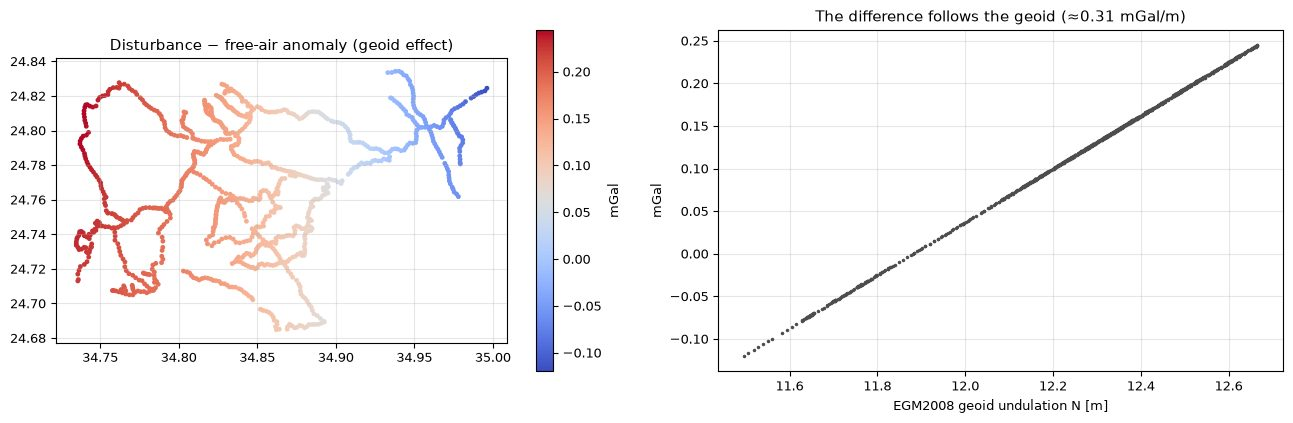

In [21]:
# 📊 RESULT
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
sc = axes[0].scatter(s["lon"], s["lat"], c=diff, s=6, cmap="coolwarm")
plt.colorbar(sc, ax=axes[0], label="mGal")
axes[0].set(aspect=1 / np.cos(np.radians(24.76)), title="Disturbance − free-air anomaly (geoid effect)")
axes[1].plot(s["N_egm2008_m"], diff, ".", ms=3, color="0.3")
axes[1].set(xlabel="EGM2008 geoid undulation N [m]", ylabel="mGal", title="The difference follows the geoid (≈0.31 mGal/m)")
plt.tight_layout()

## 10  Bouguer correction with Harmonica, checked with Choclo

`harmonica.bouguer_correction` returns the attraction 2πGρH of an infinite slab. As a check, **Choclo** (the kernel
library under Harmonica) computes the field of one very wide, thin prism, which must equal the slab.

In [22]:
# ✏️ PARAMETERS – edit and re-run from here
RHO = 2.67              # g/cm³, reduction density for the maps

In [23]:
# ▶ PROCESSING
# Choclo check: a 200 km x 200 km x 100 m prism, observed 1 m above its top centre.
# Choclo returns the UPWARD component g_u (m/s²); the gravimeter measures g_z = -g_u (downward).
g_prism = -choclo.prism.gravity_u(0.0, 0.0, 101.0, -1e5, 1e5, -1e5, 1e5, 0.0, 100.0, RHO * 1000) * 1e5
g_slab = hm.bouguer_correction(np.array([100.0]), density_crust=RHO * 1000)[0]
print(f"Choclo prism: {g_prism:.4f} mGal   Harmonica slab: {g_slab:.4f} mGal   ratio {g_prism / g_slab:.5f}")

H, H100 = st["H_ortho_m"], b100["H_used"]
bc = hm.bouguer_correction(H.values, density_crust=RHO * 1000) - hm.bouguer_correction(np.array([H100]), density_crust=RHO * 1000)[0]
st["SB_rel_mgal"] = st[PRODUCT_COL] - bc
s = st[st["product_ok"]]
print(f"simple Bouguer ({PRODUCT}, ρ = {RHO}): {s['SB_rel_mgal'].min():.2f} … {s['SB_rel_mgal'].max():.2f} mGal")

Choclo prism: 11.1917 mGal   Harmonica slab: 11.1969 mGal   ratio 0.99954
simple Bouguer (disturbance, ρ = 2.67): -14.37 … 10.03 mGal


## 11  Terrain correction with Harmonica prisms

Two prism models of the Copernicus GLO-30 DEM are compared, both computed with Harmonica (Choclo kernels):

* **A, Fatiando-style layer:** the DEM projected to a regular 200 m UTM grid (`verde.project_grid`) and turned into
  one `harmonica.prism_layer`. This is simple and fast, but 200 m cells are coarse near the stations and Earth curvature
  is ignored.
* **B, zoned model** (`wghadir.gravity.terrain.TopoModel`): 1″ (~30 m) prisms within about ±2 km, about 250 m
  block-averaged prisms out to 22 km, Earth curvature, and a flattened DEM within 50 m of each station.

The difference between A and B shows how much the near-field detail matters. `TERRAIN_MODEL` selects the model used
for the complete Bouguer anomaly. Run time is about 1 minute.

In [24]:
# ✏️ PARAMETERS – edit and re-run from here
TERRAIN_MODEL = "zoned"         # "zoned" (B, recommended) | "layer" (A)
LAYER_SPACING_M = 200.0         # cell size of the simple layer (smaller = slower)

In [25]:
# ▶ PROCESSING
tic = time.time()
# B: zoned model -> unit topographic effect u_topo relative to base 100 (mGal per g/cm³)
topo_model = terrain.TopoModel(dem)
st = reductions.terrain_stage(st, ref, topo_model, progress=False)

# A: Fatiando-style single prism layer
dem_da = xr.DataArray(dem.z[::3, ::3], coords={"latitude": dem.lat[::3], "longitude": dem.lon[::3]},
                      dims=("latitude", "longitude")).sortby("latitude")
topo_utm = vd.project_grid(dem_da, projection=UTM, spacing=LAYER_SPACING_M, method="linear")
surface = np.where(np.isfinite(topo_utm.values), np.maximum(topo_utm.values, 0.0), 0.0)      # sea = no mass
layer = hm.prism_layer((topo_utm.easting, topo_utm.northing), surface=surface, reference=0.0,
                       properties={"density": np.full(surface.shape, 1000.0)})                 # 1 g/cm³
e, n = UTM(st["lon"].values, st["lat"].values)
ok = st["product_ok"].values
g_layer = np.full(len(st), np.nan)
g_layer[ok] = layer.prism_layer.gravity((e[ok], n[ok], st["H_ortho_m"].values[ok] + 0.2), field="g_z")
eb, nb = UTM(b100["lon"], b100["lat"])
g_layer_100 = layer.prism_layer.gravity((np.array([eb]), np.array([nb]), np.array([b100["H_used"] + 0.2])), field="g_z")[0]
st["u_layer_mgal_per_gcc"] = g_layer - g_layer_100
U_COL = {"zoned": "u_topo_mgal_per_gcc", "layer": "u_layer_mgal_per_gcc"}[TERRAIN_MODEL]
st["CB_rel_mgal"] = st[PRODUCT_COL] - RHO * st[U_COL]
s = st[st["product_ok"]]
dU = RHO * (s["u_layer_mgal_per_gcc"] - s["u_topo_mgal_per_gcc"])
print(f"done in {time.time() - tic:.0f} s;  layer − zoned (ρ = {RHO}): mean {dU.mean():+.2f}, std {dU.std():.2f}, "
      f"max |Δ| {dU.abs().max():.2f} mGal")

done in 49 s;  layer − zoned (ρ = 2.67): mean -0.73, std 0.80, max |Δ| 3.64 mGal


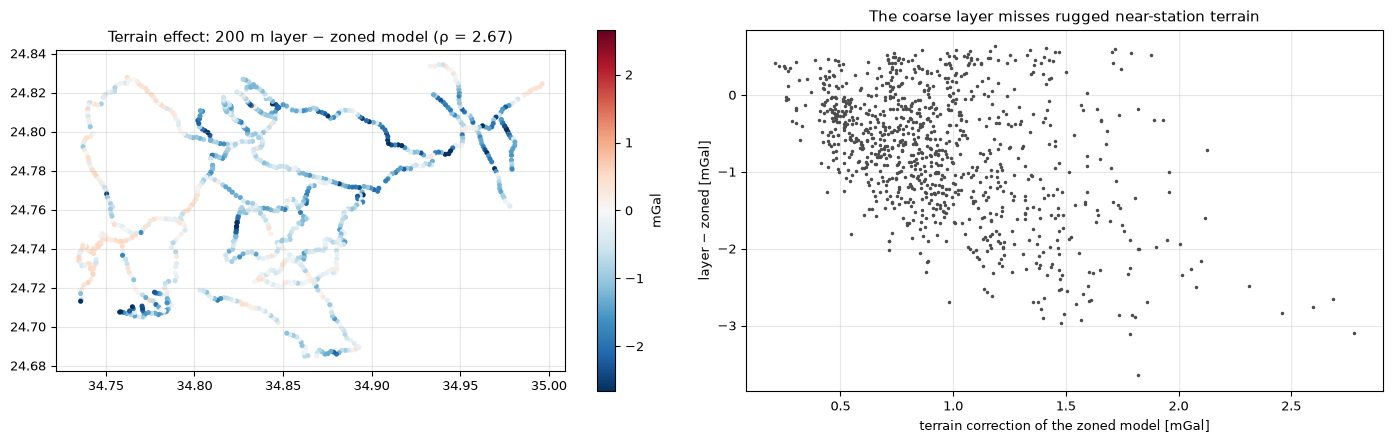

In [26]:
# 📊 RESULT
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
lim = np.nanpercentile(np.abs(dU), 98)
sc = axes[0].scatter(s["lon"], s["lat"], c=dU, s=7, cmap="RdBu_r", vmin=-lim, vmax=lim)
plt.colorbar(sc, ax=axes[0], label="mGal")
axes[0].set(aspect=1 / np.cos(np.radians(24.76)), title=f"Terrain effect: 200 m layer − zoned model (ρ = {RHO})")
axes[1].plot(s["TC_rho2.67_mgal"], dU, ".", ms=3, color="0.3")
axes[1].set(xlabel="terrain correction of the zoned model [mGal]", ylabel="layer − zoned [mGal]",
            title="The coarse layer misses rugged near-station terrain")
plt.tight_layout()

## 12  Reduction density: Nettleton

The Nettleton density of each profile is computed for the quantity selected in step 9 (`density.*`).

In [27]:
# ▶ PROCESSING
prof, prof_summary = density.build_profiles(st)
sweeps, net = density.run_nettleton(prof, prof_summary, value_col=PRODUCT_COL)
win = density.window_nettleton(prof)
consensus = density.density_consensus(net, win)
consensus.round(3)

,set,method,n,weighted_mean,weighted_se,median,p25,p75,chi2,dof,p_value,birge_ratio,weighted_se_scaled
0,profiles,simple,15,2.306,0.041,2.935,1.637,3.183,1477.952,14,0.0,10.275,0.418
1,profiles,complete,19,2.527,0.032,2.036,1.351,2.928,960.165,18,0.0,7.304,0.232
2,3km_windows,simple,16,3.053,0.077,3.149,2.102,3.430,57.481,15,0.0,1.958,0.150
3,3km_windows,complete,32,2.786,0.044,2.529,1.571,3.017,179.998,31,0.0,2.410,0.107


## 13  Gridding: Verde spline versus Harmonica equivalent sources

Both methods are fitted to the complete Bouguer values in UTM 36N and compared by block K-fold cross-validation
(`verde.cross_val_score`):

* **Spline:** block median, linear trend and biharmonic spline (Verde), as in the delivered maps.
* **Equivalent sources** (`harmonica.EquivalentSources`): point sources at a constant depth below the stations
  reproduce the data. They honour the station heights and can predict the field at a constant height.

The equivalent-source depth and damping are chosen from `EQS_DEPTHS` × `EQS_DAMPINGS` by cross-validation.
`GRID_METHOD = "auto"` takes the method with the smaller error.

In [28]:
# ✏️ PARAMETERS – edit and re-run from here
GRID_SPACING_M = 100.0
GRID_HEIGHT_M = 450.0                       # equivalent sources: prediction height (above all stations)
EQS_DEPTHS = (1000.0, 2000.0, 3000.0, 5000.0)
EQS_DAMPINGS = (0.1, 1.0, 10.0)
SPLINE_DAMPING = 1e-7
MASK_KM = 2.0
GRID_METHOD = "auto"                        # "auto" | "spline" | "eqs"

In [29]:
# ▶ PROCESSING
s = st[st["product_ok"]]
e, n = UTM(s["lon"].values, s["lat"].values)
up = s["H_ortho_m"].values + 0.2
values = s["CB_rel_mgal"].values
cv = vd.BlockKFold(spacing=2000, n_splits=5, shuffle=True, random_state=0)
spline = vd.Chain([("block", vd.BlockReduce(np.median, spacing=200)), ("trend", vd.Trend(degree=1)),
                   ("spline", vd.Spline(damping=SPLINE_DAMPING, mindist=50.0))])
cv_spline = -np.mean(vd.cross_val_score(spline, (e, n), values, cv=cv, scoring="neg_root_mean_squared_error"))
scores = []
for depth in EQS_DEPTHS:
    for damping in EQS_DAMPINGS:
        eqs = hm.EquivalentSources(depth=depth, damping=damping, block_size=200)
        sc = -np.mean(vd.cross_val_score(eqs, (e, n, up), values, cv=cv, scoring="neg_root_mean_squared_error"))
        scores.append(dict(depth=depth, damping=damping, cv_rmse_mgal=sc))
scores = pd.DataFrame(scores).sort_values("cv_rmse_mgal")
best = scores.iloc[0]
method = GRID_METHOD if GRID_METHOD != "auto" else ("eqs" if best["cv_rmse_mgal"] < cv_spline else "spline")
print(f"spline: {cv_spline:.3f} mGal;  best equivalent sources: depth {best['depth']:.0f} m, damping {best['damping']} "
      f"-> {best['cv_rmse_mgal']:.3f} mGal;  used: {method}")

region = (e.min() - MASK_KM * 1000, e.max() + MASK_KM * 1000, n.min() - MASK_KM * 1000, n.max() + MASK_KM * 1000)
GE, GN = vd.grid_coordinates(region, spacing=GRID_SPACING_M)
if method == "eqs":
    model = hm.EquivalentSources(depth=best["depth"], damping=best["damping"], block_size=200).fit((e, n, up), values)
    Z = model.predict((GE, GN, np.full_like(GE, GRID_HEIGHT_M)))
else:
    Z = spline.fit((e, n), values).predict((GE, GN))
grid = vd.make_xarray_grid((GE, GN), Z, data_names="cb", dims=("northing", "easting")).cb
from scipy.spatial import cKDTree
dist_to_data = cKDTree(np.column_stack([e, n])).query(np.column_stack([GE.ravel(), GN.ravel()]))[0].reshape(GE.shape)
mask = dist_to_data <= MASK_KM * 1000
print("grid", grid.shape)
scores.round(3).head(6)

spline: 0.664 mGal;  best equivalent sources: depth 3000 m, damping 0.1 -> 0.718 mGal;  used: spline


grid (208, 304)


,depth,damping,cv_rmse_mgal
6,3000.0,0.1,0.718
3,2000.0,0.1,0.758
4,2000.0,1.0,0.786
7,3000.0,1.0,0.789
10,5000.0,1.0,0.794
9,5000.0,0.1,0.801


[None,
 Text(0.5, 0, 'easting [km]'),
 Text(0, 0.5, 'northing [km]'),
 Text(0.5, 1.0, 'Complete Bouguer disturbance, ρ = 2.67, gridded with spline')]

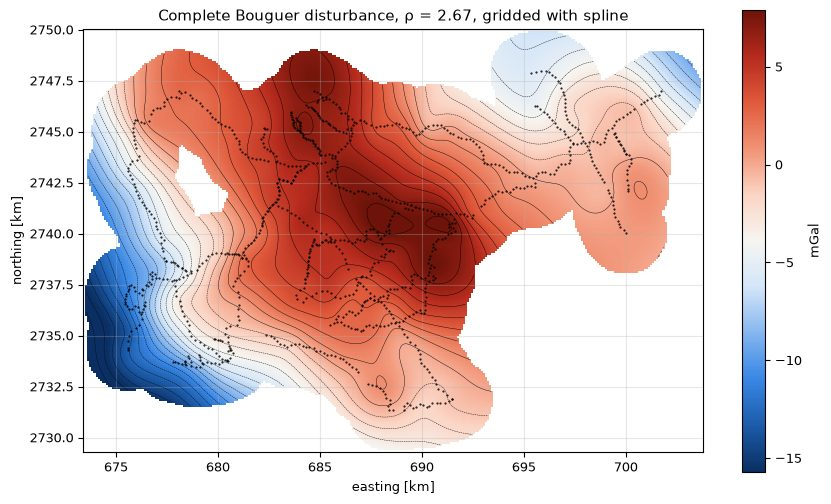

In [30]:
# 📊 RESULT
fig, ax = plt.subplots(figsize=(10, 6))
lo, hi = np.nanpercentile(np.where(mask, grid, np.nan), [1, 99])
m = ax.pcolormesh(grid.easting / 1000, grid.northing / 1000, np.where(mask, grid, np.nan), cmap=mapping.ANOM,
                  vmin=lo, vmax=hi, shading="auto")
ax.contour(grid.easting / 1000, grid.northing / 1000, np.where(mask, grid, np.nan), levels=np.arange(-30, 30, 1),
           colors="k", linewidths=0.3)
ax.plot(e / 1000, n / 1000, ".", ms=1, color="k")
plt.colorbar(m, ax=ax, label="mGal")
ax.set(aspect="equal", xlabel="easting [km]", ylabel="northing [km]",
       title=f"Complete Bouguer {PRODUCT}, ρ = {RHO}, gridded with {method}")

## 14  Regional and residual (Harmonica filters)

The **regional** field is the grid upward-continued by `UPWARD_M` (`harmonica.upward_continuation`), which keeps
the broad field of deep sources. The **residual** = grid − regional and enhances shallow sources. As an alternative,
`harmonica.gaussian_highpass` removes wavelengths longer than `HIGHPASS_WAVELENGTH_M`. The grid is padded
(`xrft.pad`) to reduce edge effects.

In [31]:
# ✏️ PARAMETERS – edit and re-run from here
UPWARD_M = 3000.0
HIGHPASS_WAVELENGTH_M = 8000.0

In [32]:
# ▶ PROCESSING
level = float(grid.mean())
pad = {"easting": grid.easting.size // 3, "northing": grid.northing.size // 3}
padded = xrft.pad(grid - level, pad)
regional = xrft.unpad(hm.upward_continuation(padded, height_displacement=UPWARD_M), pad) + level
highpass = xrft.unpad(hm.gaussian_highpass(padded, wavelength=HIGHPASS_WAVELENGTH_M), pad)
regional = regional.assign_coords(easting=grid.easting, northing=grid.northing)
highpass = highpass.assign_coords(easting=grid.easting, northing=grid.northing)
residual = grid - regional
print(f"residual: {float(residual.where(mask).min()):.2f} … {float(residual.where(mask).max()):.2f} mGal")

residual: -12.75 … 5.84 mGal


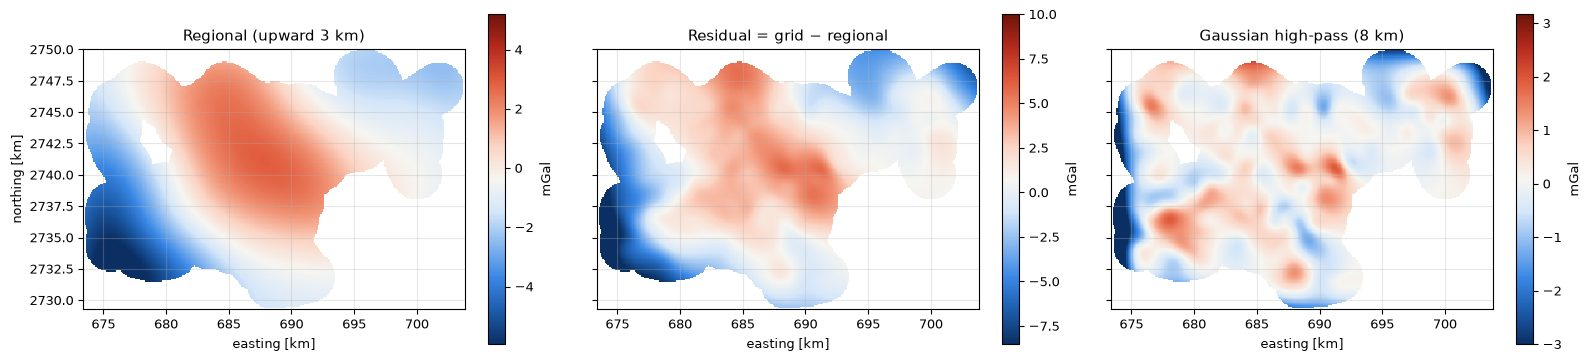

In [33]:
# 📊 RESULT
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for ax, g, title in ((axes[0], regional, f"Regional (upward {UPWARD_M / 1000:g} km)"),
                     (axes[1], residual, "Residual = grid − regional"),
                     (axes[2], highpass, f"Gaussian high-pass ({HIGHPASS_WAVELENGTH_M / 1000:g} km)")):
    v = np.where(mask, g, np.nan)
    lim = np.nanpercentile(np.abs(v - np.nanmedian(v)), 98)
    m = ax.pcolormesh(g.easting / 1000, g.northing / 1000, v, cmap=mapping.ANOM, shading="auto",
                      vmin=np.nanmedian(v) - lim, vmax=np.nanmedian(v) + lim)
    plt.colorbar(m, ax=ax, shrink=0.8, label="mGal")
    ax.set(aspect="equal", title=title, xlabel="easting [km]")
axes[0].set_ylabel("northing [km]")
plt.tight_layout()

## 15  Edges and derivatives: SGTool and Harmonica

Derivative-based maps outline the edges of density contrasts. The **SGTool** filter engine (Jessell et al.; vendored
in `third_party/sgtool`) computes the vertical derivative (1VD), total horizontal gradient (THG), tilt angle and
analytic signal of the residual. Derivatives amplify short wavelengths, so the residual is first smoothed with
`harmonica.gaussian_lowpass` (`DERIV_LOWPASS_M`; set 0 to switch it off).

Sign convention: SGTool takes z positive **down**, so its 1VD and tilt are positive over a dense body. Harmonica's
`derivative_upward` and `tilt_angle` take z positive **up**, with the opposite sign. The cross-check below
therefore compares SGTool with −Harmonica.

In [34]:
# ✏️ PARAMETERS – edit and re-run from here
SGTOOL_BUFFER = 10        # padding cells used by SGTool
DERIV_LOWPASS_M = 1500.0  # smoothing before the derivatives (0 = none)

In [35]:
# ▶ PROCESSING
gp = sgtool_processor(dx=GRID_SPACING_M, dy=GRID_SPACING_M, buffer=SGTOOL_BUFFER)
smooth = residual
if DERIV_LOWPASS_M > 0:
    smooth = xrft.unpad(hm.gaussian_lowpass(xrft.pad(residual, pad), wavelength=DERIV_LOWPASS_M), pad)
    smooth = smooth.assign_coords(easting=grid.easting, northing=grid.northing)
R = smooth.values
edges = {
    "1VD [mGal/m]": gp.compute_derivative(R, "z", buffer_size=SGTOOL_BUFFER),
    "THG [mGal/m]": gp.total_horizontal_gradient(R, buffer_size=SGTOOL_BUFFER),
    "Tilt angle [rad]": gp.tilt_angle(R, buffer_size=SGTOOL_BUFFER),
    "Analytic signal [mGal/m]": gp.analytic_signal(R, buffer_size=SGTOOL_BUFFER),
}
hm_tilt = -xrft.unpad(hm.tilt_angle(xrft.pad(smooth, pad)), pad).values        # sign: z up -> z down
sg_tilt = edges["Tilt angle [rad]"]
both = mask & np.isfinite(hm_tilt) & np.isfinite(sg_tilt)
print(f"tilt angle, SGTool vs (−)Harmonica: correlation {np.corrcoef(sg_tilt[both], hm_tilt[both])[0, 1]:.3f} "
      "(differences come from the padding and derivative filters of the two codes)")

tilt angle, SGTool vs (−)Harmonica: correlation 0.909 (differences come from the padding and derivative filters of the two codes)


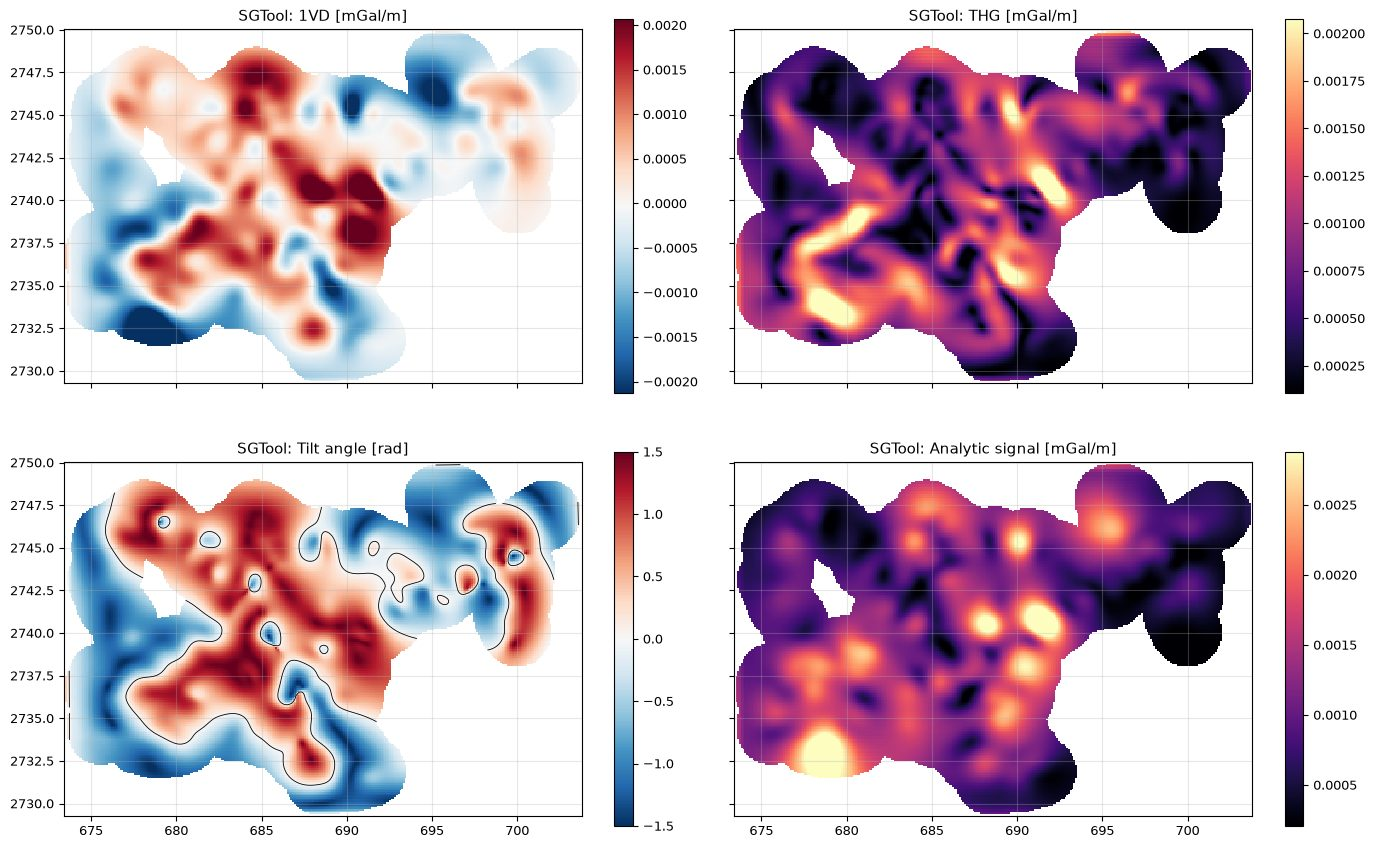

In [36]:
# 📊 RESULT
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
for ax, (name, v) in zip(axes.ravel(), edges.items()):
    v = np.where(mask, v, np.nan)
    if name.startswith("Tilt"):
        m = ax.pcolormesh(grid.easting / 1000, grid.northing / 1000, v, cmap="RdBu_r", vmin=-1.5, vmax=1.5, shading="auto")
        ax.contour(grid.easting / 1000, grid.northing / 1000, v, levels=[0], colors="k", linewidths=0.6)
    else:
        lo, hi = np.nanpercentile(v, [2, 98])
        m = ax.pcolormesh(grid.easting / 1000, grid.northing / 1000, v, cmap="magma" if "1VD" not in name else "RdBu_r",
                          vmin=lo, vmax=hi, shading="auto")
    plt.colorbar(m, ax=ax, shrink=0.85)
    ax.set(aspect="equal", title=f"SGTool: {name}")
plt.tight_layout()

## 16  Publication maps with PyGMT

**PyGMT** (the Python interface to the Generic Mapping Tools) draws the final maps: the anomaly shaded with the
Copernicus relief, contours, stations and the coastline (the 0 m DEM contour), all in UTM 36N kilometres. Change the
colour map (`CMAP`, any GMT or scientific colour map, e.g. `"vik"`, `"roma"`, `"polar"`) and re-run.

In [37]:
# ✏️ PARAMETERS – edit and re-run from here
CMAP = "vik"
MAP_WIDTH_CM = 15

In [38]:
# ▶ PROCESSING
km = lambda g: g.assign_coords(easting=g.easting / 1000, northing=g.northing / 1000).rename(easting="x", northing="y")
reg_km = [float(grid.easting.min()) / 1000, float(grid.easting.max()) / 1000,
          float(grid.northing.min()) / 1000, float(grid.northing.max()) / 1000]
height_cm = MAP_WIDTH_CM * (reg_km[3] - reg_km[2]) / (reg_km[1] - reg_km[0])
proj = f"X{MAP_WIDTH_CM}c/{height_cm:.2f}c"
RE, RN = vd.grid_coordinates((float(grid.easting.min()), float(grid.easting.max()),
                               float(grid.northing.min()), float(grid.northing.max())), spacing=50.0)
rlon, rlat = UTM(RE, RN, inverse=True)
relief = vd.make_xarray_grid((RE, RN), dem.sample(rlon.ravel(), rlat.ravel()).reshape(RE.shape), data_names="z",
                             dims=("northing", "easting")).z           # 1″ DEM sampled on a 50 m UTM grid
relief = km(relief.fillna(0)).astype("float32")
shade = pygmt.grdgradient(grid=relief, radiance=[315, 40], normalize="t0.7")
st_km = pd.DataFrame({"x": e / 1000, "y": n / 1000})


def gmt_panel(fig, g, title, unit, cmap=CMAP, symmetric=True, contours="auto"):
    # one map panel at the current plot origin
    """One PyGMT map panel: relief, anomaly, contours, stations, coast and colour bar."""
    v = g.where(mask)
    lo, hi = np.nanpercentile(v, [1, 99])
    if symmetric:
        c = float(np.nanmedian(v)); a = max(abs(lo - c), abs(hi - c)); lo, hi = c - a, c + a
    fig.grdimage(grid=relief, cmap="gray", shading=shade, region=reg_km, projection=proj, transparency=30,
                 frame=["WSne+t" + title, "xaf+lEasting (km, UTM 36N)", "yaf+lNorthing (km)"])
    pygmt.makecpt(cmap=cmap, series=[lo, hi])
    fig.grdimage(grid=km(v).astype("float32"), cmap=True, nan_transparent=True, transparency=15)
    if contours == "auto":
        fig.grdcontour(grid=km(v).astype("float32"), levels=(hi - lo) / 16, pen="0.2p,black@40")
    elif contours is not None:
        fig.grdcontour(grid=km(v).astype("float32"), levels=contours, pen="0.5p,black")
    fig.plot(data=st_km, style="c0.04c", fill="black@30")
    fig.grdcontour(grid=relief, levels=[0.5], pen="0.8p,dodgerblue3")          # coastline
    fig.colorbar(frame=[f"af+l{unit}"], position="JMR+o0.4c/0c+w6c/0.3c")


pygmt.config(FONT_ANNOT_PRIMARY="7p", FONT_LABEL="8p", FONT_TITLE="10p,Helvetica-Bold", MAP_FRAME_TYPE="plain")
fig = pygmt.Figure()
panels = [(grid, f"Complete Bouguer {PRODUCT} (rho = {RHO})", "mGal", CMAP, True, "auto"),
          (residual, f"Residual (upward {UPWARD_M / 1000:g} km removed)", "mGal", CMAP, True, "auto"),
          (xr.DataArray(edges["THG [mGal/m]"] * 1000, coords=grid.coords, dims=grid.dims),
           "Total horizontal gradient (SGTool)", "mGal/km", "lajolla", False, None),
          (xr.DataArray(edges["Tilt angle [rad]"], coords=grid.coords, dims=grid.dims), "Tilt angle (SGTool, 0 contour)",
           "rad", "vik", True, [0])]
dx, dy = MAP_WIDTH_CM + 4.0, height_cm + 2.6
for i, (g, title, unit, cmap, sym, cont) in enumerate(panels):
    if i == 1 or i == 3:
        fig.shift_origin(xshift=f"{dx}c")
    if i == 2:
        fig.shift_origin(xshift=f"{-dx}c", yshift=f"{-dy}c")
    gmt_panel(fig, g, title, unit, cmap=cmap, symmetric=sym, contours=cont)
fig.savefig(os.path.join(OUT_DIR, "pygmt_gravity_maps.png"), dpi=300)

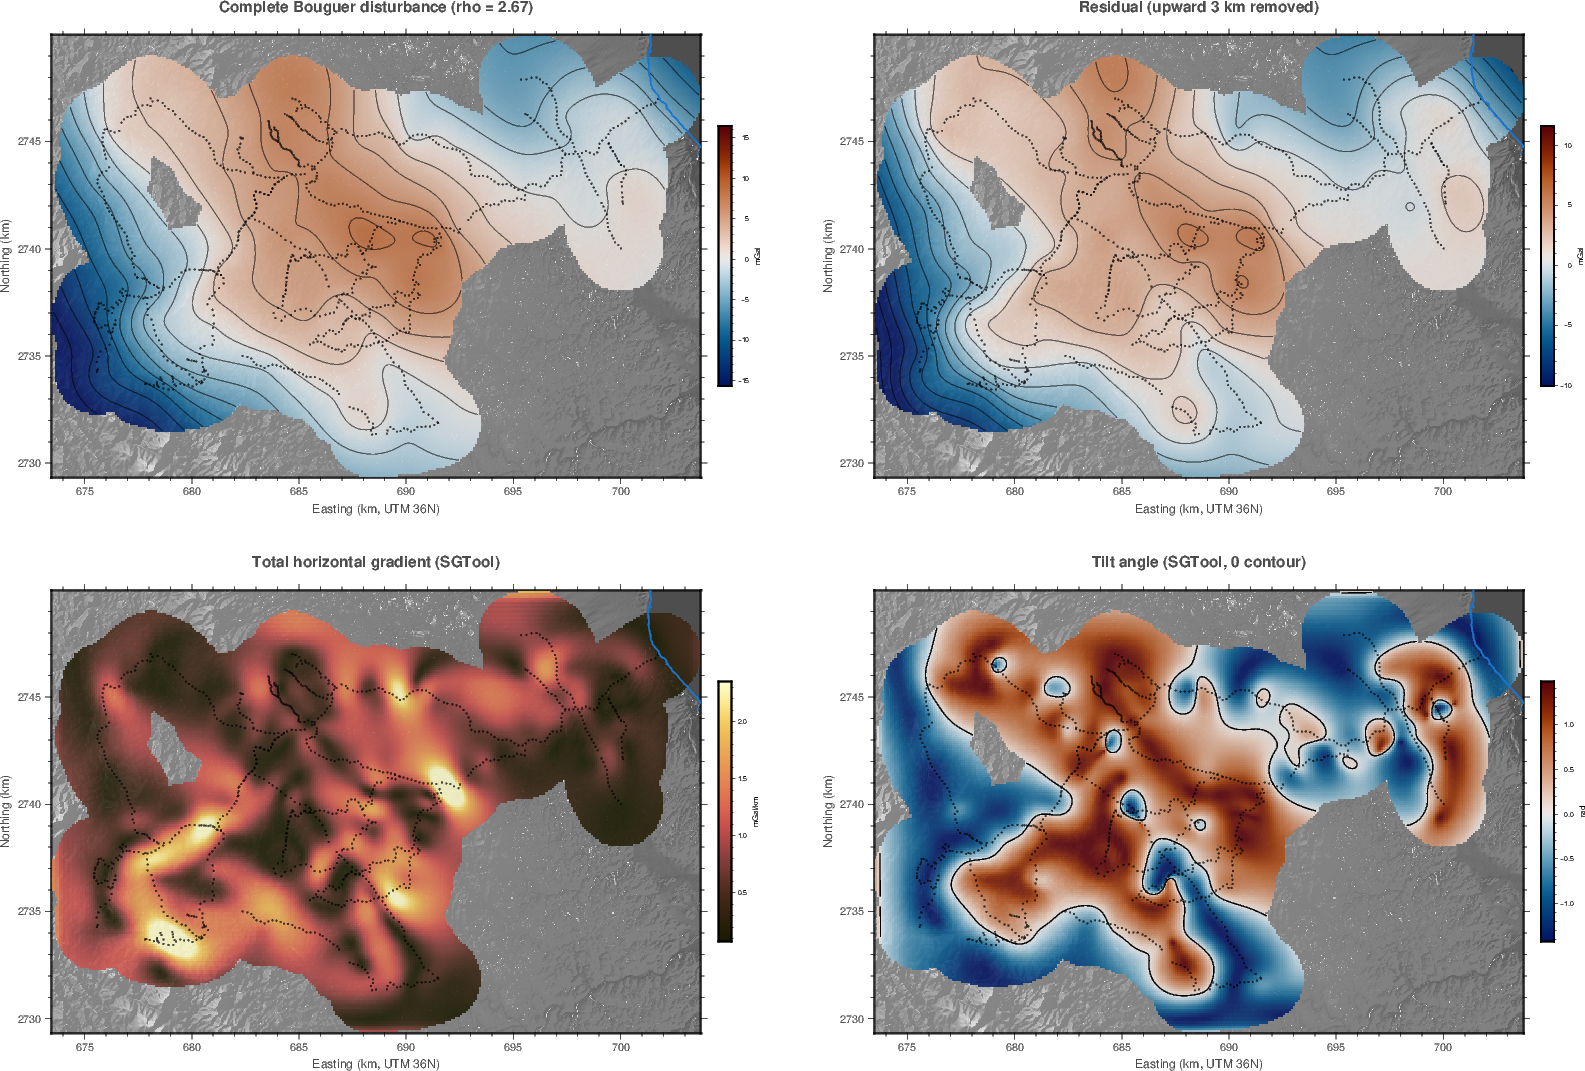

In [39]:
# 📊 RESULT
fig.show(dpi=110, width=1100)      # preview; the 300 dpi file is in outputs/open_source/

## 17  Export

Writes the station table and the grids of this workflow to `outputs/open_source/`:
`Wadi_Ghadir_OpenSource_Stations.csv` and `Wadi_Ghadir_OpenSource_Grids.nc`
(complete Bouguer, regional, residual and the SGTool edge grids, UTM 36N), plus the PyGMT figure. The table ends
with the difference to the delivered product, which shows the combined effect of the choices made here.

In [40]:
# ▶ PROCESSING
s = st[st["product_ok"]].copy()
s["tide_model"], s["product"], s["terrain_model"], s["rho"] = TIDE_MODEL, PRODUCT, TERRAIN_MODEL, RHO
cols = ["occ_key", "instrument", "date", "line", "station", "lat", "lon", "h_used", "H_ortho_m", "N_egm2008_m",
        "dg100_scaled_mgal", "dFA_rel_mgal", "dist_rel_mgal", "SB_rel_mgal", "u_topo_mgal_per_gcc",
        "u_layer_mgal_per_gcc", "CB_rel_mgal", "tide_model", "product", "terrain_model", "rho"]
s[cols].to_csv(os.path.join(OUT_DIR, "Wadi_Ghadir_OpenSource_Stations.csv"), index=False, float_format="%.6f")
ds = xr.Dataset({"complete_bouguer": grid, "regional": regional, "residual": residual,
                 **{k.split(" [")[0].replace(" ", "_").lower(): (grid.dims, v) for k, v in edges.items()}})
ds["data_mask"] = (grid.dims, mask)
ds.attrs.update(crs="EPSG:32636", author="Dr. Mohamed Sobh, LIAG", tide=TIDE_MODEL, product=PRODUCT,
                terrain=TERRAIN_MODEL, density=RHO, gridding=method)
ds.to_netcdf(os.path.join(OUT_DIR, "Wadi_Ghadir_OpenSource_Grids.nc"))
delivered = pd.read_csv(os.path.join(REPO, "outputs", "deliverables", "Wadi_Ghadir_Final_Stations.csv"))
cmp = s.drop_duplicates("occ_key").merge(delivered[["Station_UID", "CB_rel_2.67_mGal"]].drop_duplicates("Station_UID"),
                                         left_on="occ_key", right_on="Station_UID", how="inner")
dd = cmp["CB_rel_mgal"] - cmp["CB_rel_2.67_mGal"]
print(f"vs delivered CB (2.67): n = {len(dd)}, mean {dd.mean():+.3f} mGal, std {dd.std():.3f} mGal")
print("written:", sorted(os.listdir(OUT_DIR)))

vs delivered CB (2.67): n = 984, mean +0.119 mGal, std 0.083 mGal
written: ['Wadi_Ghadir_OpenSource_Grids.nc', 'Wadi_Ghadir_OpenSource_Stations.csv', 'pygmt_gravity_maps.png']


---
### References

* Fatiando a Terra Project: Harmonica, Verde, Boule, Choclo, https://www.fatiando.org (Uieda et al. 2013; Uieda 2018).
* Wenzel, H.-G. (1996), The nanogal software: Earth tide data processing package ETERNA 3.30. Bull. Inf. Marées Terrestres 124; pygtide, https://github.com/hydrogeoscience/pygtide.
* Longman, I. M. (1959), Formulas for computing the tidal accelerations due to the Moon and the Sun. JGR 64.
* Hinze, W. J. et al. (2005), New standards for reducing gravity data: the North American gravity database. Geophysics 70.
* Li, X. & Götze, H.-J. (2001), Ellipsoid, geoid, gravity, geodesy, and geophysics. Geophysics 66.
* Jessell, M. et al., SGTool – Structural Geophysics Tools, https://github.com/swaxi/SGTool (MIT).
* Tian, D. et al. (2024), PyGMT: A Python interface for the Generic Mapping Tools; Wessel, P. et al. (2019), GMT 6.

*Prepared by Dr. Mohamed Sobh, LIAG.*